In [ ]:
!unzip NoGlasses/no_glasses.zip -d NoGlasses

Archive:  NoGlasses/no_glasses.zip
   creating: NoGlasses/no_glasses/
  inflating: NoGlasses/no_glasses/-afro-muestra-dientes-blancos-estando-buen-humor-despues-clases_273609-16608.jpg  
  inflating: NoGlasses/no_glasses/0x0.jpg  
  inflating: NoGlasses/no_glasses/1000_F_203495429_ZfUUkMGXeDJ0Ec253Vbr44cVK4QWGFPg.jpg  
  inflating: NoGlasses/no_glasses/101124_WEB_LFJ_History-and-the-Power-of-Place-Charles-Person.jpg  
  inflating: NoGlasses/no_glasses/1200px-Am_i_a_bad_person_quiz.png  
  inflating: NoGlasses/no_glasses/1200px-Andrzej_Person_Kancelaria_Senatu.jpg  
  inflating: NoGlasses/no_glasses/16297800391_5c6e812832.jpg  
  inflating: NoGlasses/no_glasses/209a8e165db455e39695d8112c954531c25d1503c683cce8f3571e65d3c38e8c._SX1080_FMpng_.png  
  inflating: NoGlasses/no_glasses/35844588650_3ebd4096b1_b-934x460.jpg  
  inflating: NoGlasses/no_glasses/360_F_243123463_zTooub557xEWABDLk0jJklDyLSGl2jrr.jpg  
  inflating: NoGlasses/no_glasses/360_F_302884605_actpipOdPOQHDTnFtp4zg4RtlWzhOASp.

In [ ]:
!unzip WithGlasses/with_glasses.zip -d WithGlasses

Archive:  WithGlasses/with_glasses.zip
   creating: WithGlasses/with_glasses/
  inflating: WithGlasses/with_glasses/-weird-young-man-wearing-glasses-isolated-on-white-background-confident-nerd.jpg  
  inflating: WithGlasses/with_glasses/110382059-portrait-of-attractive-casual-man-wearing-glasses-standing-on-light-grey-background.jpg  
  inflating: WithGlasses/with_glasses/131608649-close-up-picture-of-a-good-looking-young-man-wearing-glasses.jpg  
  inflating: WithGlasses/with_glasses/2322807-CLONE-Market-What-to-Know-About-EyeBuyDirect-1296x728-header-f0d9d5.jpg  
  inflating: WithGlasses/with_glasses/360_F_166722458_FOMSZb1FwjYJlkS1ZPONURruypZYDa8I.jpg  
  inflating: WithGlasses/with_glasses/360_F_336979582_9YQipUAfPEfKF6gZ5EfzT5b8U3vWJsFJ.jpg  
  inflating: WithGlasses/with_glasses/360_F_500869314_L7cwLLpthd2EBGIgNBgJiARtKseqnbe8.jpg  
  inflating: WithGlasses/with_glasses/360_F_502151561_oZKT2pDgQokfhU7del9rJcMQMiT22eGJ.jpg  
  inflating: WithGlasses/with_glasses/38774735-closeup-o

In [ ]:
!rm -rf NoGlasses/no_glasses.zip
!rm -rf WithGlasses/with_glasses.zip

In [ ]:
!mkdir dataset
!cp -r NoGlasses dataset/NoGlasses
!cp -r WithGlasses dataset/WithGlasses

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=10,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],
    horizontal_flip=True,
    validation_split=0.2
)

data_gen_entrenamiento = datagen.flow_from_directory("/content/dataset",
                                                     target_size=(224,224),
                                                     batch_size=32, shuffle=True,
                                                     subset="training")
data_gen_pruebas = datagen.flow_from_directory("/content/dataset",
                                               target_size=(224,224),
                                               batch_size=32, shuffle = True,
                                               subset = "validation")

Found 170 images belonging to 2 classes.
Found 42 images belonging to 2 classes.


/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


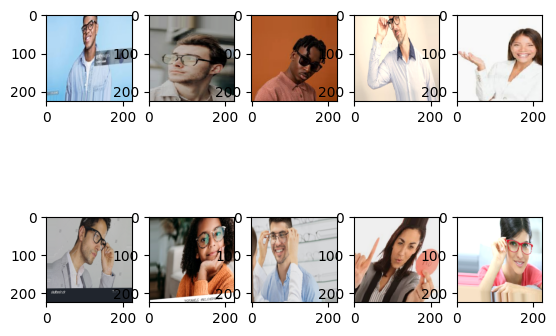

In [ ]:
import matplotlib.pyplot as plt
for imagen, etiqueta in data_gen_entrenamiento:
  for i in range(10):
    plt.subplot(2,5, i+1)
    plt.imshow(imagen[i])
  break
plt.show()

In [ ]:
!pip install tf_keras


In [ ]:
import tensorflow as tf
import tf_keras as tfk
import tensorflow_hub as hub

# Cargar el modelo preentrenado desde TensorFlow Hub
url = "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4"
feature_extractor_layer = hub.KerasLayer(url, input_shape=(224, 224, 3))
feature_extractor_layer.trainable = True


In [ ]:
modelo = tfk.Sequential([
    feature_extractor_layer,
    tfk.layers.Dense(128, activation='relu'),
    tfk.layers.Dropout(0.3),  # regularización para evitar overfitting
    tfk.layers.Dense(2, activation='softmax')
])

In [ ]:
modelo.compile(
    optimizer=tfk.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
import tensorflow as tf
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

In [ ]:
EPOCAS = 20
steps_per_epoch = data_gen_entrenamiento.samples // data_gen_entrenamiento.batch_size
validation_steps = data_gen_pruebas.samples // data_gen_pruebas.batch_size

entrenamiento = modelo.fit(
    data_gen_entrenamiento,
    epochs=EPOCAS,
    steps_per_epoch=steps_per_epoch,
    validation_data=data_gen_pruebas,
    validation_steps=validation_steps
)

Epoch 1/20
4/5 [=======================>......] - ETA: 0s - loss: 0.8679 - accuracy: 0.5283

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


5/5 [==============================] - 34s 1s/step - loss: 0.8483 - accuracy: 0.5435 - val_loss: 0.6775 - val_accuracy: 0.5938
Epoch 2/20
5/5 [==============================] - 3s 682ms/step - loss: 0.5691 - accuracy: 0.7609 - val_loss: 0.6852 - val_accuracy: 0.5938
Epoch 3/20
5/5 [==============================] - 6s 1s/step - loss: 0.5030 - accuracy: 0.8125 - val_loss: 0.6792 - val_accuracy: 0.6250
Epoch 4/20
5/5 [==============================] - 3s 724ms/step - loss: 0.3359 - accuracy: 0.9275 - val_loss: 0.8005 - val_accuracy: 0.6250
Epoch 5/20
5/5 [==============================] - 4s 856ms/step - loss: 0.2718 - accuracy: 0.9275 - val_loss: 0.8320 - val_accuracy: 0.5938
Epoch 6/20
5/5 [==============================] - 5s 1s/step - loss: 0.2423 - accuracy: 0.9493 - val_loss: 0.7176 - val_accuracy: 0.6562
Epoch 7/20
5/5 [==============================] - 4s 872ms/step - loss: 0.1918 - accuracy: 0.9638 - val_loss: 0.8593 - val_accuracy: 0.5625
Epoch 8/20
5/5 [=======================

In [ ]:
from PIL import Image
import cv2

def categorizar(ruta):
  img = Image.open(ruta)
  img = img.convert("RGB")
  img = np.array(img).astype(float)/255

  img = cv2.resize(img,(224,224))
  prediccion = modelo.predict(img.reshape(-1,224,224,3))
  return np.argmax(prediccion[0], axis=-1)

In [ ]:
ruta = "conLentes1.jpg"
prediccion = categorizar(ruta)
print(prediccion)

1/1 [==============================] - 0s 91ms/step
1


In [ ]:
ruta = "sinLentes2.jpg"
prediccion = categorizar(ruta)
print(prediccion)

1/1 [==============================] - 0s 111ms/step
0
